# **Import Libraries**

In [1]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns
pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")


Libraries imported successfully!


# **Load Dataset**

In [2]:

# Load the retail sales dataset

df = pd.read_csv('retail_sales_dataset.csv')

# Display first 5 rows
df.head()


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


# **Initialization**

In [3]:

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns)

# Check data types
print("\nData Types:")
print(df.dtypes)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())


Dataset Shape: (1000, 9)

Column Names:
Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='object')

Data Types:
Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate Rows: 0


# **Descriptive Statistics**

In [4]:

# Descriptive statistics

print("Mean:")
print(df.mean(numeric_only=True))

print("\nMedian:")
print(df.median(numeric_only=True))

print("\nMode:")
print(df.mode().iloc[0])

print("\nStandard Deviation:")
print(df.std(numeric_only=True))


Mean:
Transaction ID    500.500
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

Median:
Transaction ID    500.5
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

Mode:
Transaction ID               1
Date                2023-05-16
Customer ID            CUST001
Gender                  Female
Age                       43.0
Product Category      Clothing
Quantity                   4.0
Price per Unit            50.0
Total Amount              50.0
Name: 0, dtype: object

Standard Deviation:
Transaction ID    288.819436
Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64


# **Sales Distribution**

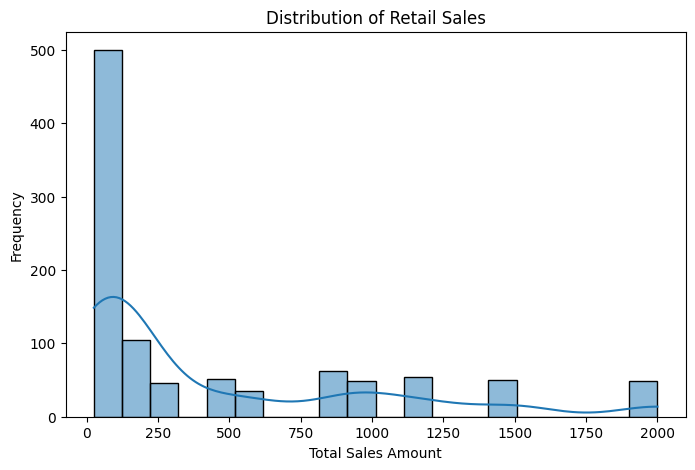

In [5]:

plt.figure(figsize=(8,5))

sns.histplot(df['Total Amount'], bins=20, kde=True)

plt.title("Distribution of Retail Sales")
plt.xlabel("Total Sales Amount")
plt.ylabel("Frequency")

plt.show()


# **Monthly and Quarterly Sales Trends**

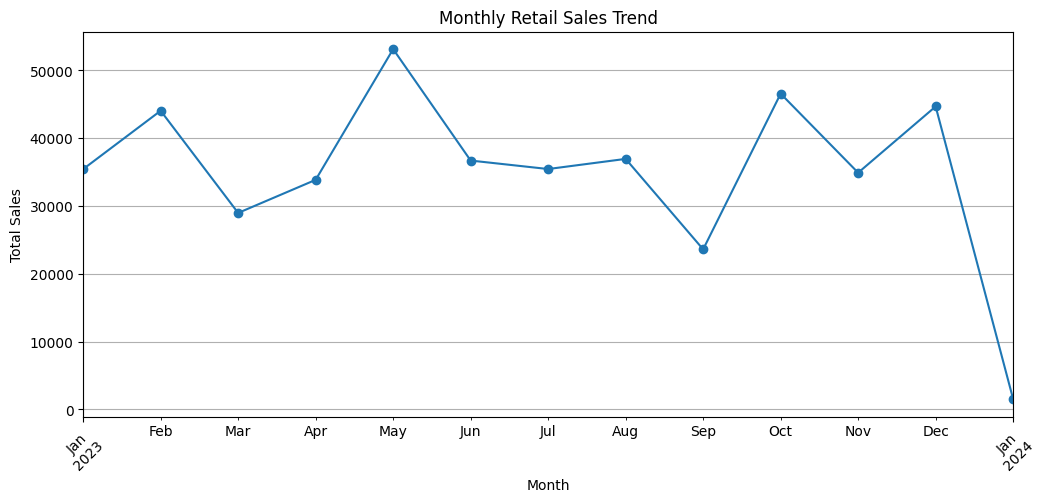

In [6]:

# Convert Date column into datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Extract month and year
df['Month'] = df['Date'].dt.to_period('M')

# Calculate monthly sales
monthly_sales = df.groupby('Month')['Total Amount'].sum()

# Plot monthly sales
plt.figure(figsize=(12,5))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Retail Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)

plt.show()


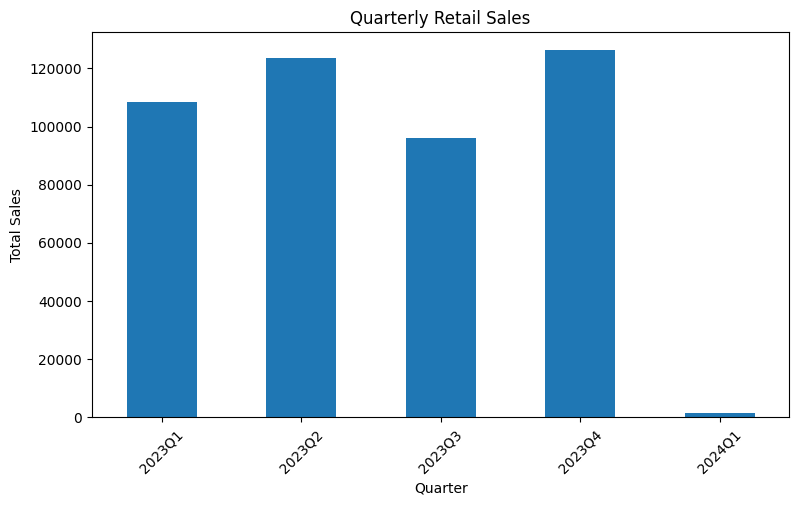

In [7]:

# Extract quarter
df['Quarter'] = df['Date'].dt.to_period('Q')

# Calculate quarterly sales
quarterly_sales = df.groupby('Quarter')['Total Amount'].sum()

# Plot quarterly sales
plt.figure(figsize=(9,5))

quarterly_sales.plot(kind='bar')

plt.title('Quarterly Retail Sales')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

plt.show()


# **Customer Demographics Analysis**

# Customer Age Distribution

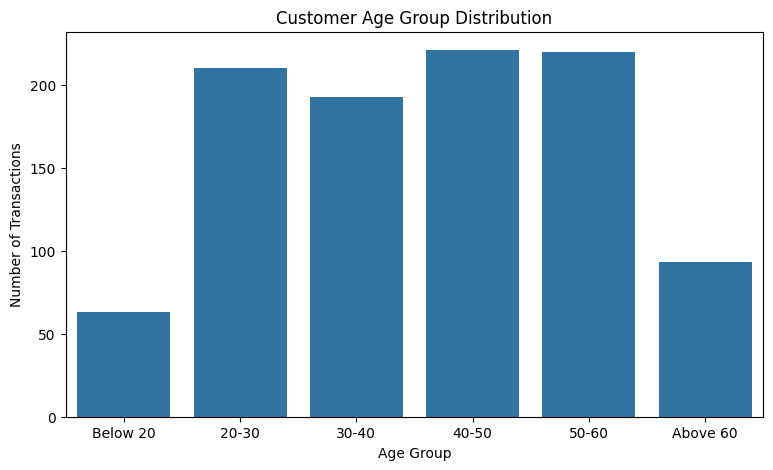

In [8]:

# Create age groups

df['Age Group'] = pd.cut(
    df['Age'],
    bins=[0, 20, 30, 40, 50, 60, 100],
    labels=['Below 20', '20-30', '30-40',
            '40-50', '50-60', 'Above 60']
)

# Count customers in each age group
age_counts = df['Age Group'].value_counts().sort_index()

# Plot age distribution
plt.figure(figsize=(9,5))

sns.barplot(x=age_counts.index, y=age_counts.values)

plt.title('Customer Age Group Distribution')
plt.xlabel('Age Group')
plt.ylabel('Number of Transactions')

plt.show()


# Gender Distribution

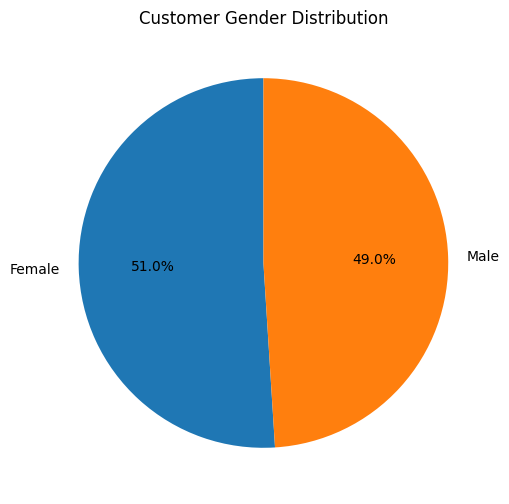

Gender
Female    510
Male      490
Name: count, dtype: int64


In [9]:

# Count gender distribution

gender_counts = df['Gender'].value_counts()

# Create pie chart
plt.figure(figsize=(6,6))

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Gender Distribution')

plt.show()

print(gender_counts)


# **Customer demographics**

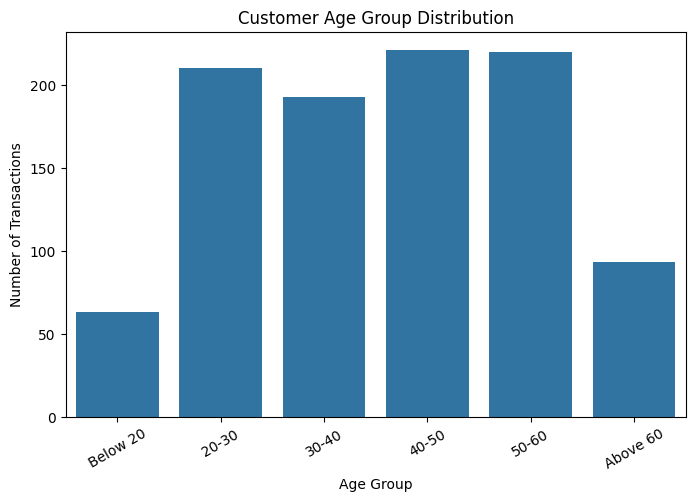

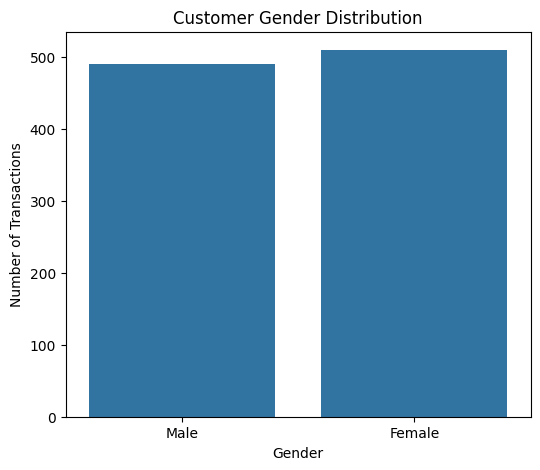

Gender Counts:
Gender
Female    510
Male      490
Name: count, dtype: int64


In [10]:

# 1. Customer Age Group Analysis

df['Age Group'] = pd.cut(
    df['Age'],
    bins=[0, 20, 30, 40, 50, 60, 100],
    labels=['Below 20', '20-30', '30-40',
            '40-50', '50-60', 'Above 60']
)

plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Age Group')
plt.title('Customer Age Group Distribution')
plt.xlabel('Age Group')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=30)
plt.show()


# 2. Gender Analysis

plt.figure(figsize=(6,5))
sns.countplot(data=df, x='Gender')
plt.title('Customer Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Transactions')
plt.show()

print("Gender Counts:")
print(df['Gender'].value_counts())


# **Product category analysis**

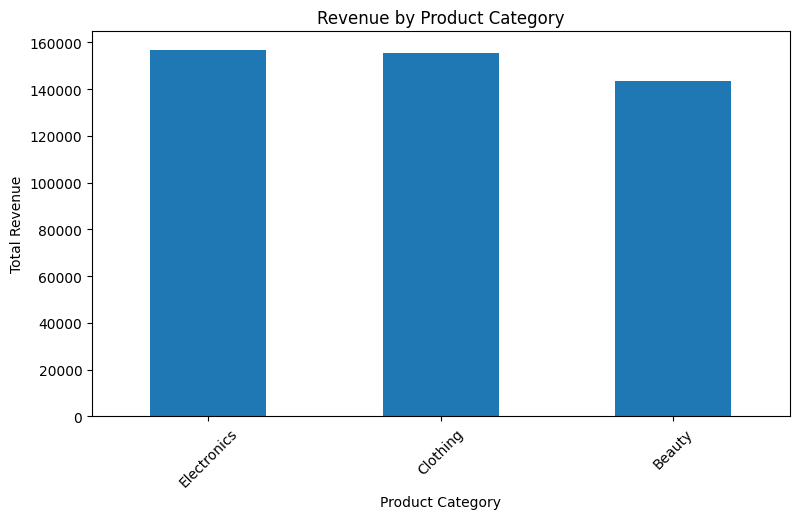

Category Revenue:
Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


In [11]:

# Top selling product categories

category_sales = df.groupby('Product Category')['Total Amount'].sum().sort_values(ascending=False)

plt.figure(figsize=(9,5))
category_sales.plot(kind='bar')
plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.show()

print("Category Revenue:")
print(category_sales)


# **Correlation heatmap**

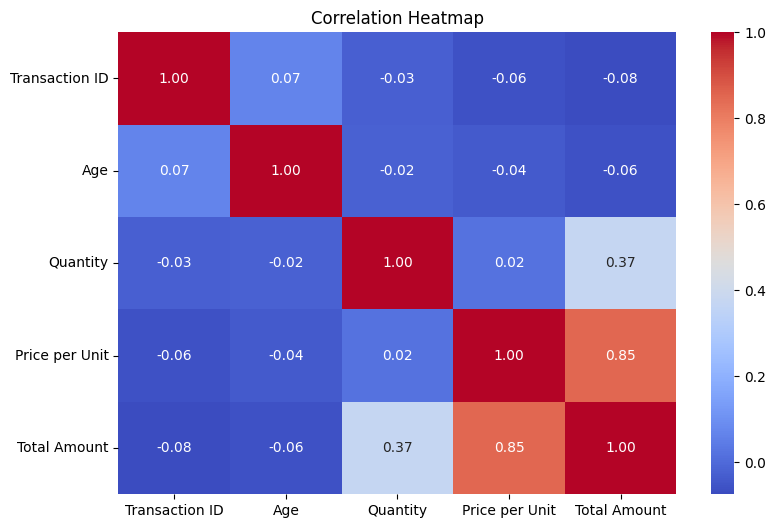

In [12]:

# Correlation matrix

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(9,6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()


# **Additional visualization**

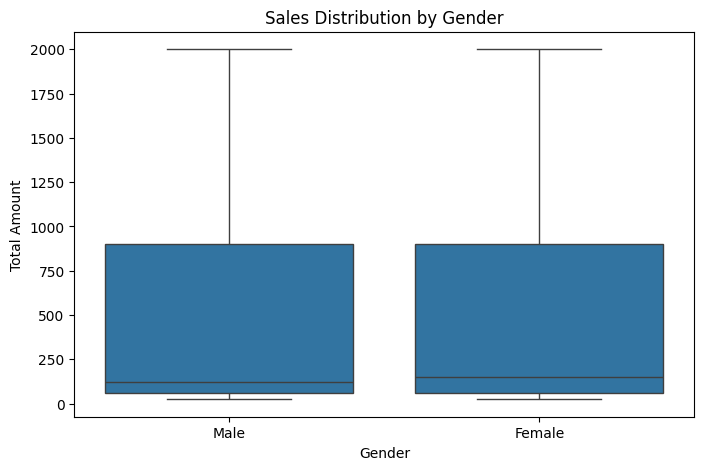

In [13]:

# Sales by Gender

plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='Gender',
    y='Total Amount'
)

plt.title('Sales Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Total Amount')
plt.show()


# **Final observations and recommendations**


# Conclusion and Business Recommendations

## Key Findings

1. The retail sales dataset contains 1000 transactions and 9 columns.
2. No missing values were found during initial inspection.
3. Sales distribution is positively skewed, indicating some high-value transactions.
4. Monthly and quarterly sales show fluctuations over time.
5. Customer demographics and product category analysis help identify customer behaviour and revenue patterns.
6. Correlation analysis helps understand relationships between numerical variables.

## Business Recommendations

1. Focus marketing campaigns on customer age groups with higher transaction counts.
2. Promote product categories generating higher revenue.
3. Analyze low-sales months and introduce targeted promotional offers.
4. Use customer purchase patterns to improve inventory planning.
5. Monitor sales trends regularly to support better business decisions.

## Final Conclusion

Exploratory Data Analysis helps businesses understand sales performance, customer behaviour and product category performance. The analysis can support better marketing, inventory management and business decision-making.
